# Airbus Ship Segmentation | YOLOv8-seg + OpenCV

- Task: find ships on 768×768 satellite images and draw a mask for each one (Airbus Ship Detection, ~192,000 images, ~78% without ships).
- Metric: simplified competition F2 per image (averaged over IoU 0.5–0.95), plus separate scores for images with and without ships.
- Baseline "no ships everywhere": F2 0.797. YOLOv8n-seg (5,000 training images, 15 epochs, conf 0.5): F2 0.861.
- Experiment: lowering the confidence threshold to 0.25 finds more ships but adds false alarms, with no overall gain.
- Numbers come from the original run; a re-run may differ slightly (GPU training is not fully deterministic).
- Experiment 2: 30 epochs instead of 15 (training was still improving); see the final table.


## 1: Setup and quick look

In [1]:
!pip install -q ultralytics

In [2]:
import os, random
import numpy as np
import pandas as pd

DATA_DIR = "/kaggle/input/competitions/airbus-ship-detection"
IMG_DIR = f"{DATA_DIR}/train_v2"
CSV_PATH = f"{DATA_DIR}/train_ship_segmentations_v2.csv"
WORK_DIR = "/kaggle/working"
IMG_SIZE = 768  # original image size
SEED = 42
random.seed(SEED); np.random.seed(SEED)

def rle_decode(rle, shape=(IMG_SIZE, IMG_SIZE)):
    """Turn an RLE string into a 0/1 mask."""
    s = np.array(rle.split(), dtype=int)
    starts, lengths = s[0::2] - 1, s[1::2]  # RLE is 1-indexed
    mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    for st, ln in zip(starts, lengths):
        mask[st:st + ln] = 1
    return mask.reshape(shape, order="F")  # competition uses column-major order

print(os.path.exists(CSV_PATH), len(os.listdir(IMG_DIR)))

True 192556


In [3]:
df = pd.read_csv(CSV_PATH)
ships = df.groupby("ImageId")["EncodedPixels"].count()  # count() skips NaN = no ship

print("images:", len(ships))
print("empty share:", round((ships == 0).mean(), 3))
print(ships[ships > 0].value_counts().sort_index().head(6).to_string())

images: 192556
empty share: 0.779
EncodedPixels
1    27104
2     7674
3     2954
4     1622
5      925
6      657


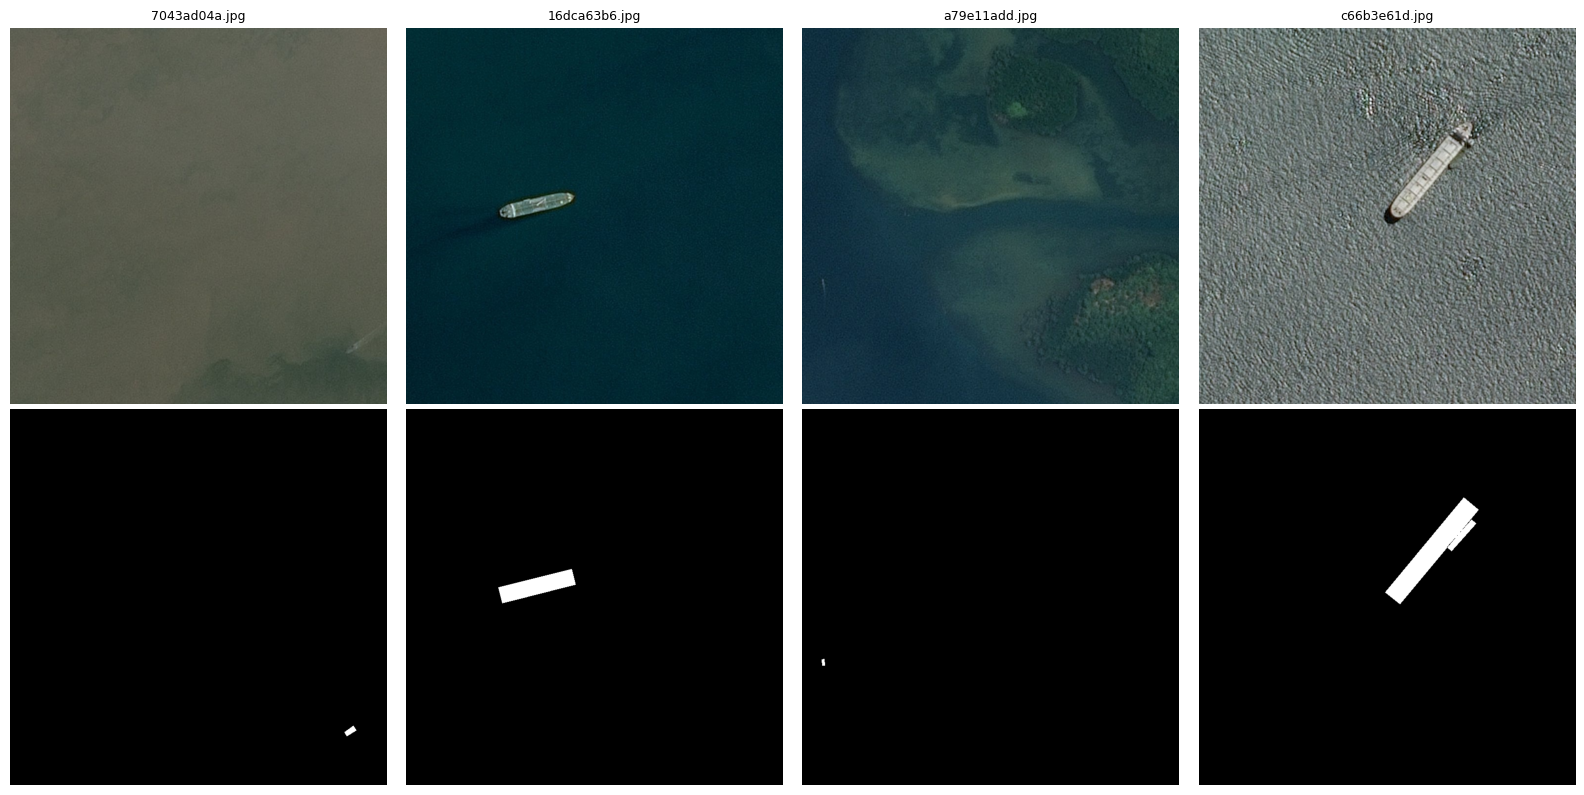

In [4]:
import matplotlib.pyplot as plt
from PIL import Image

df = pd.read_csv(CSV_PATH)
with_ships = df.dropna()["ImageId"].unique()
sample = np.random.default_rng(SEED).choice(with_ships, 4, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, img_id in enumerate(sample):
    mask = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    for rle in df.loc[df.ImageId == img_id, "EncodedPixels"]:
        mask |= rle_decode(rle)
    axes[0, i].imshow(Image.open(f"{IMG_DIR}/{img_id}"))
    axes[1, i].imshow(mask, cmap="gray")
    axes[0, i].set_title(img_id, fontsize=9)
    for a in axes[:, i]: a.axis("off")
plt.tight_layout(); plt.show()

- Loaded 192,556 images and their RLE masks.
- ~78% of images have no ships, so accuracy would be misleading; we use F2 instead.
- Most images with ships contain only 1–2 ships, and ships are very small.
- Decision: train on a ~6,000-image subset to fit the time budget.

## 2: Baseline and data prep

In [5]:
%%writefile /kaggle/working/metric.py
import numpy as np

def f2_image(gt_masks, pred_masks):
    """Simplified competition metric for one image: F2 averaged over IoU 0.5..0.95."""
    if len(gt_masks) == 0 and len(pred_masks) == 0:
        return 1.0  # correctly said "no ships"
    if len(gt_masks) == 0 or len(pred_masks) == 0:
        return 0.0  # false alarm, or missed all ships
    gt = np.stack(gt_masks).reshape(len(gt_masks), -1).astype(np.float32)
    pr = np.stack(pred_masks).reshape(len(pred_masks), -1).astype(np.float32)
    inter = pr @ gt.T  # overlap in pixels, shape (n_pred, n_gt)
    iou = inter / (pr.sum(1)[:, None] + gt.sum(1)[None, :] - inter)
    scores = []
    for t in np.arange(0.5, 1.0, 0.05):
        hit = iou > t
        tp = hit.any(1).sum()
        fp = len(pr) - tp
        fn = len(gt) - hit.any(0).sum()
        scores.append(5 * tp / (5 * tp + 4 * fn + fp))  # F2 formula
    return float(np.mean(scores))

Writing /kaggle/working/metric.py


In [6]:
SPLIT = {"train_ship": 4000, "train_empty": 1000, "val_total": 2000}

df = pd.read_csv(CSV_PATH)
n_ships = df.groupby("ImageId")["EncodedPixels"].count()
ship_ids = n_ships[n_ships > 0].index.to_numpy()
empty_ids = n_ships[n_ships == 0].index.to_numpy()
empty_ids = empty_ids[empty_ids != "6384c3e78.jpg"]  # known corrupted file
rng = np.random.default_rng(SEED)
rng.shuffle(ship_ids); rng.shuffle(empty_ids)

train = list(ship_ids[:SPLIT["train_ship"]]) + list(empty_ids[:SPLIT["train_empty"]])
rest = np.concatenate([ship_ids[SPLIT["train_ship"]:], empty_ids[SPLIT["train_empty"]:]])
val = list(rng.choice(rest, SPLIT["val_total"], replace=False))  # natural ratio

split = pd.DataFrame({"ImageId": train + val,
                      "split": ["train"] * len(train) + ["val"] * len(val)})
split.to_csv(f"{WORK_DIR}/split.csv", index=False)
print(split.split.value_counts().to_dict(), "| val with ships:", int((n_ships[val] > 0).sum()))

{'train': 5000, 'val': 2000} | val with ships: 406


In [7]:
from metric import f2_image

df = pd.read_csv(CSV_PATH)
split = pd.read_csv(f"{WORK_DIR}/split.csv")
gt = df.dropna().groupby("ImageId")["EncodedPixels"].apply(list)  # id -> list of RLE
val_ids = split.loc[split.split == "val", "ImageId"]

# baseline: predict "no ships" on every image (empty prediction list)
scores = [f2_image([rle_decode(r) for r in gt.get(i, [])], []) for i in val_ids]
val_df = pd.DataFrame({"ImageId": val_ids.values, "has_ship": val_ids.isin(gt.index).values, "f2": scores})
val_df.to_csv(f"{WORK_DIR}/val_scores_baseline.csv", index=False)

groups = {"all images": val_df,
          "images without ships": val_df[~val_df.has_ship],
          "images with ships": val_df[val_df.has_ship]}
print("Baseline: predict 'no ships' on every val image\n")
for label, g in groups.items():
    print(f"  F2, {label:<22} ({len(g):>4} images):  {g.f2.mean():.3f}")

Baseline: predict 'no ships' on every val image

  F2, all images             (2000 images):  0.797
  F2, images without ships   (1594 images):  1.000
  F2, images with ships      ( 406 images):  0.000


In [8]:
import cv2

df = pd.read_csv(CSV_PATH)
split = pd.read_csv(f"{WORK_DIR}/split.csv")
gt = df.dropna().groupby("ImageId")["EncodedPixels"].apply(list)
YOLO_DIR = f"{WORK_DIR}/yolo"

for img_id, part in zip(split.ImageId, split.split):
    os.makedirs(f"{YOLO_DIR}/images/{part}", exist_ok=True)
    os.makedirs(f"{YOLO_DIR}/labels/{part}", exist_ok=True)
    dst = f"{YOLO_DIR}/images/{part}/{img_id}"
    if not os.path.exists(dst):
        os.symlink(f"{IMG_DIR}/{img_id}", dst)
    lines = []
    for rle in gt.get(img_id, []):
        mask = np.ascontiguousarray(rle_decode(rle))
        cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        c = max(cnts, key=cv2.contourArea).reshape(-1, 2) / IMG_SIZE  # normalize to 0..1
        if len(c) >= 3:  # a polygon needs at least 3 points
            lines.append("0 " + " ".join(f"{v:.5f}" for v in c.flatten()))
    with open(f"{YOLO_DIR}/labels/{part}/{img_id.replace('.jpg', '.txt')}", "w") as f:
        f.write("\n".join(lines))

print(len(os.listdir(f"{YOLO_DIR}/labels/train")), len(os.listdir(f"{YOLO_DIR}/labels/val")))

5000 2000


In [9]:
import yaml

cfg = {"path": f"{WORK_DIR}/yolo", "train": "images/train", "val": "images/val", "names": {0: "ship"}}
with open(f"{WORK_DIR}/yolo/data.yaml", "w") as f:
    yaml.safe_dump(cfg, f)
print(open(f"{WORK_DIR}/yolo/data.yaml").read())

names:
  0: ship
path: /kaggle/working/yolo
train: images/train
val: images/val



- Split: 5,000 train images (80% with ships) and 2,000 val images with the natural ~78% empty ratio.
- Baseline "no ships everywhere" gives F2 = 0.797 overall but 0.0 on images with ships.
- Converted RLE masks to YOLO polygons (one polygon per ship).
- Val has only 406 ship images, so differences below ~0.01 may be noise.

## 3: Model training and evaluation

In [10]:
import os
os.environ["YOLO_VERBOSE"] = "False"  # must be set before importing ultralytics
from ultralytics import YOLO, settings
settings.update({"raytune": False})  # disable Ray Tune callback (only causes warnings here)

EXP = {"name": "yolov8n_seg_768", "model": "yolov8n-seg.pt",
       "imgsz": 768, "epochs": 15, "batch": 16}

model = YOLO(EXP["model"])  # pretrained weights download automatically
_ = model.train(data=f"{WORK_DIR}/yolo/data.yaml", imgsz=EXP["imgsz"], epochs=EXP["epochs"],
                batch=EXP["batch"], seed=SEED, deterministic=True, plots=False,
                project=f"{WORK_DIR}/runs", name=EXP["name"], exist_ok=True, verbose=False)
print("Best weights:", os.path.exists(f"{WORK_DIR}/runs/{EXP['name']}/weights/best.pt"))

Best weights: True


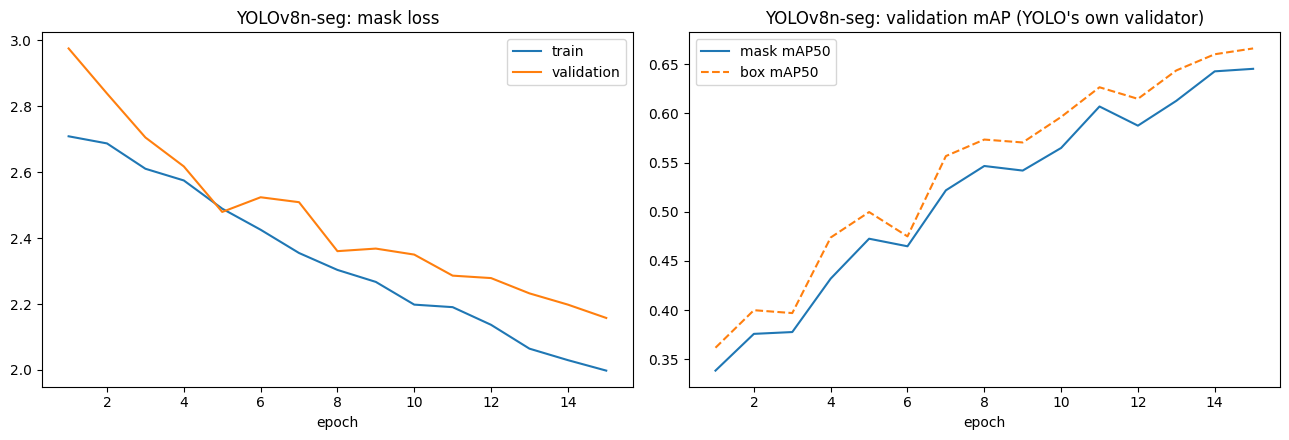

In [11]:
import matplotlib.pyplot as plt

hist = pd.read_csv(f"{WORK_DIR}/runs/yolov8n_seg_768/results.csv")
hist.columns = hist.columns.str.strip()  # older ultralytics adds spaces to column names

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist.epoch, hist["train/seg_loss"], label="train")
axes[0].plot(hist.epoch, hist["val/seg_loss"], label="validation")
axes[0].set(title="YOLOv8n-seg: mask loss", xlabel="epoch")
axes[0].legend()
axes[1].plot(hist.epoch, hist["metrics/mAP50(M)"], label="mask mAP50")
axes[1].plot(hist.epoch, hist["metrics/mAP50(B)"], label="box mAP50", linestyle="--")
axes[1].set(title="YOLOv8n-seg: validation mAP (YOLO's own validator)", xlabel="epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig(f"{WORK_DIR}/yolo_seg_curves.png", dpi=120)
plt.show()

In [12]:
import os
os.environ["YOLO_VERBOSE"] = "False"
from ultralytics import YOLO
from metric import f2_image

EVAL = {"name": "yolov8n_seg_768", "imgsz": 768, "conf": 0.5}

df = pd.read_csv(CSV_PATH)
split = pd.read_csv(f"{WORK_DIR}/split.csv")
gt = df.dropna().groupby("ImageId")["EncodedPixels"].apply(list)
val_ids = split.loc[split.split == "val", "ImageId"]
model = YOLO(f"{WORK_DIR}/runs/{EVAL['name']}/weights/best.pt")

scores = []
for img_id in val_ids:
    r = model.predict(f"{IMG_DIR}/{img_id}", imgsz=EVAL["imgsz"], conf=EVAL["conf"],
                      retina_masks=True, verbose=False)[0]  # retina_masks: masks at 768x768
    pred = [] if r.masks is None else list(r.masks.data.cpu().numpy() > 0.5)
    scores.append(f2_image([rle_decode(x) for x in gt.get(img_id, [])], pred))

val_df = pd.DataFrame({"ImageId": val_ids.values, "has_ship": val_ids.isin(gt.index).values, "f2": scores})
val_df.to_csv(f"{WORK_DIR}/val_scores_{EVAL['name']}.csv", index=False)
print(f"Scored {len(val_df)} val images -> val_scores_{EVAL['name']}.csv")

Scored 2000 val images -> val_scores_yolov8n_seg_768.csv


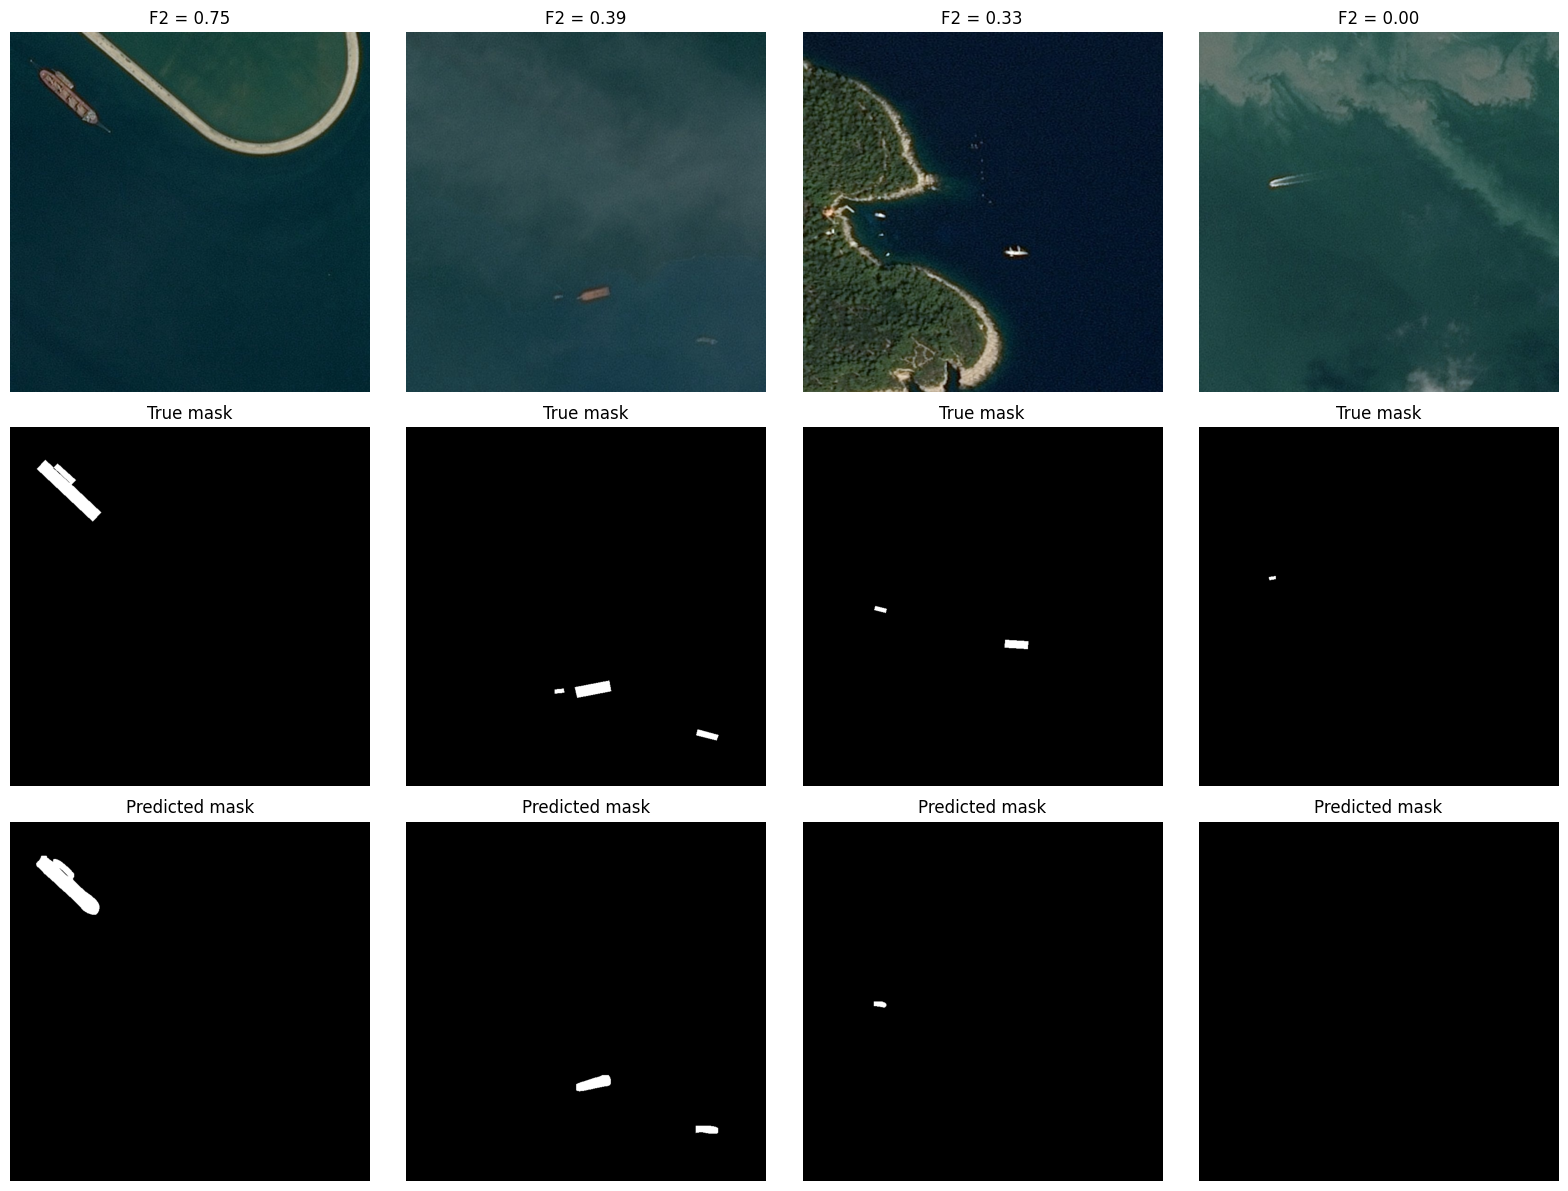

In [13]:
import os
os.environ["YOLO_VERBOSE"] = "False"
from ultralytics import YOLO
import matplotlib.pyplot as plt
from PIL import Image

EVAL = {"name": "yolov8n_seg_768", "imgsz": 768, "conf": 0.5}

df = pd.read_csv(CSV_PATH)
gt = df.dropna().groupby("ImageId")["EncodedPixels"].apply(list)
v = pd.read_csv(f"{WORK_DIR}/val_scores_{EVAL['name']}.csv")
sample = v[v.has_ship].sample(4, random_state=SEED)
model = YOLO(f"{WORK_DIR}/runs/{EVAL['name']}/weights/best.pt")

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i, (img_id, f2) in enumerate(zip(sample.ImageId, sample.f2)):
    r = model.predict(f"{IMG_DIR}/{img_id}", imgsz=EVAL["imgsz"], conf=EVAL["conf"],
                      retina_masks=True, verbose=False)[0]
    pred = np.zeros((IMG_SIZE, IMG_SIZE)) if r.masks is None else r.masks.data.cpu().numpy().max(0)
    true = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    for rle in gt[img_id]:
        true |= rle_decode(rle)
    panels = [(Image.open(f"{IMG_DIR}/{img_id}"), f"F2 = {f2:.2f}"), (true, "True mask"), (pred, "Predicted mask")]
    for row, (im, title) in enumerate(panels):
        axes[row, i].imshow(im, cmap="gray"); axes[row, i].set_title(title); axes[row, i].axis("off")
plt.tight_layout(); plt.savefig(f"{WORK_DIR}/examples.png", dpi=100); plt.show()

- Trained YOLOv8n-seg for 15 epochs at 768 px on 5,000 images (conf = 0.5).
- Overall val F2 = 0.861 vs 0.797 for the "no ships" baseline (+0.064, clearly above noise).
- Empty images: F2 = 0.996 (false alarms on only ~6 of 1,594 images).
- Images with ships: F2 = 0.33 (baseline 0.0) — the model finds ships, but masks of small ships are imprecise or missed.

## 4: Experiment: lower confidence threshold

In [14]:
import os
os.environ["YOLO_VERBOSE"] = "False"
from ultralytics import YOLO
from metric import f2_image

EXP = {"name": "yolov8n_seg_768_conf025", "run": "yolov8n_seg_768", "imgsz": 768, "conf": 0.25}

df = pd.read_csv(CSV_PATH)
split = pd.read_csv(f"{WORK_DIR}/split.csv")
gt = df.dropna().groupby("ImageId")["EncodedPixels"].apply(list)
val_ids = split.loc[split.split == "val", "ImageId"]
model = YOLO(f"{WORK_DIR}/runs/{EXP['run']}/weights/best.pt")

scores = []
for img_id in val_ids:
    r = model.predict(f"{IMG_DIR}/{img_id}", imgsz=EXP["imgsz"], conf=EXP["conf"],
                      retina_masks=True, verbose=False)[0]
    pred = [] if r.masks is None else list(r.masks.data.cpu().numpy() > 0.5)
    scores.append(f2_image([rle_decode(x) for x in gt.get(img_id, [])], pred))

val_df = pd.DataFrame({"ImageId": val_ids.values, "has_ship": val_ids.isin(gt.index).values, "f2": scores})
val_df.to_csv(f"{WORK_DIR}/val_scores_{EXP['name']}.csv", index=False)
print(f"Scored {len(val_df)} val images -> val_scores_{EXP['name']}.csv")

Scored 2000 val images -> val_scores_yolov8n_seg_768_conf025.csv


- Experiment: lowered conf from 0.5 to 0.25 (same model, no retraining).
- F2 on images with ships rose 0.330 → 0.386, but on empty images fell 0.996 → 0.976 (~38 false alarms vs ~6).
- Overall F2: 0.856 vs 0.861 — a difference below 0.01, so likely noise.
- Decision: keep conf = 0.5; because ~80% of images are empty, false alarms cost more than missed ships gain.

## 4b: Experiment 2: 30 epochs
- The training curves at 15 epochs were still improving (losses falling, mAP rising).
  The only change here: 30 epochs instead of 15. Same data, model, seed, conf 0.5.
- Expectation: higher F2 on images with ships. The result is the row `yolov8n_seg_768_e30` in the final table.

In [15]:
import os
os.environ["YOLO_VERBOSE"] = "False"
from ultralytics import YOLO, settings
settings.update({"raytune": False})  # disable Ray Tune callback (only causes warnings here)

EXP2 = {"name": "yolov8n_seg_768_e30", "model": "yolov8n-seg.pt",
        "imgsz": 768, "epochs": 30, "batch": 16}  # only change vs main run: epochs 15 -> 30

model = YOLO(EXP2["model"])
_ = model.train(data=f"{WORK_DIR}/yolo/data.yaml", imgsz=EXP2["imgsz"], epochs=EXP2["epochs"],
                batch=EXP2["batch"], seed=SEED, deterministic=True, plots=False,
                project=f"{WORK_DIR}/runs", name=EXP2["name"], exist_ok=True, verbose=False)
print("Best weights:", os.path.exists(f"{WORK_DIR}/runs/{EXP2['name']}/weights/best.pt"))

Best weights: True


In [16]:
import os
os.environ["YOLO_VERBOSE"] = "False"
from ultralytics import YOLO
from metric import f2_image

EXP = {"name": "yolov8n_seg_768_e30", "run": "yolov8n_seg_768_e30", "imgsz": 768, "conf": 0.5}

df = pd.read_csv(CSV_PATH)
split = pd.read_csv(f"{WORK_DIR}/split.csv")
gt = df.dropna().groupby("ImageId")["EncodedPixels"].apply(list)
val_ids = split.loc[split.split == "val", "ImageId"]
model = YOLO(f"{WORK_DIR}/runs/{EXP['run']}/weights/best.pt")

scores = []
for img_id in val_ids:
    r = model.predict(f"{IMG_DIR}/{img_id}", imgsz=EXP["imgsz"], conf=EXP["conf"],
                      retina_masks=True, verbose=False)[0]
    pred = [] if r.masks is None else list(r.masks.data.cpu().numpy() > 0.5)
    scores.append(f2_image([rle_decode(x) for x in gt.get(img_id, [])], pred))

val_df = pd.DataFrame({"ImageId": val_ids.values, "has_ship": val_ids.isin(gt.index).values, "f2": scores})
val_df.to_csv(f"{WORK_DIR}/val_scores_{EXP['name']}.csv", index=False)
print(f"Scored {len(val_df)} val images -> val_scores_{EXP['name']}.csv")

Scored 2000 val images -> val_scores_yolov8n_seg_768_e30.csv


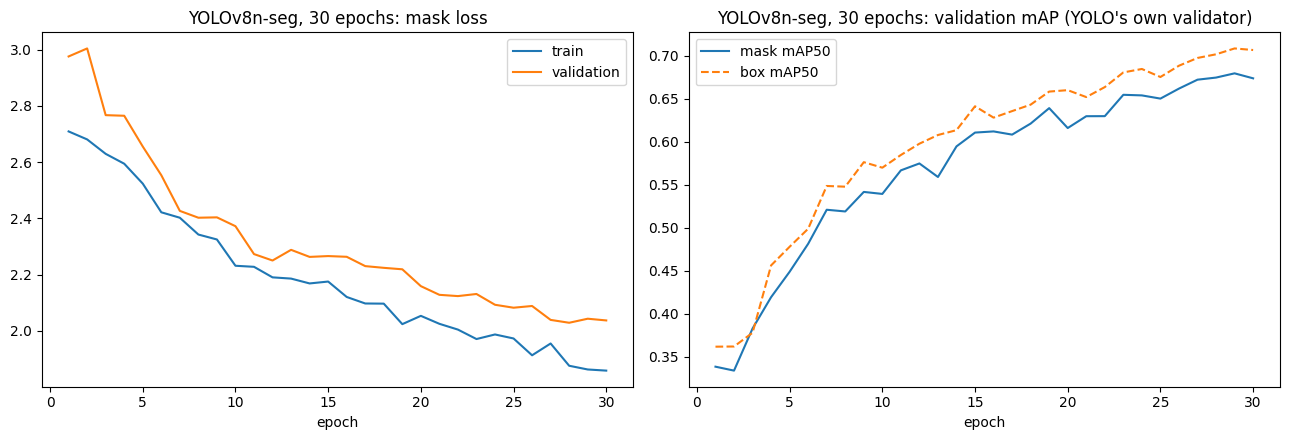

In [17]:
import matplotlib.pyplot as plt

hist = pd.read_csv(f"{WORK_DIR}/runs/yolov8n_seg_768_e30/results.csv")
hist.columns = hist.columns.str.strip()  # older ultralytics adds spaces to column names

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist.epoch, hist["train/seg_loss"], label="train")
axes[0].plot(hist.epoch, hist["val/seg_loss"], label="validation")
axes[0].set(title="YOLOv8n-seg, 30 epochs: mask loss", xlabel="epoch")
axes[0].legend()
axes[1].plot(hist.epoch, hist["metrics/mAP50(M)"], label="mask mAP50")
axes[1].plot(hist.epoch, hist["metrics/mAP50(B)"], label="box mAP50", linestyle="--")
axes[1].set(title="YOLOv8n-seg, 30 epochs: validation mAP (YOLO's own validator)", xlabel="epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig(f"{WORK_DIR}/yolo_seg_curves_e30.png", dpi=120)
plt.show()

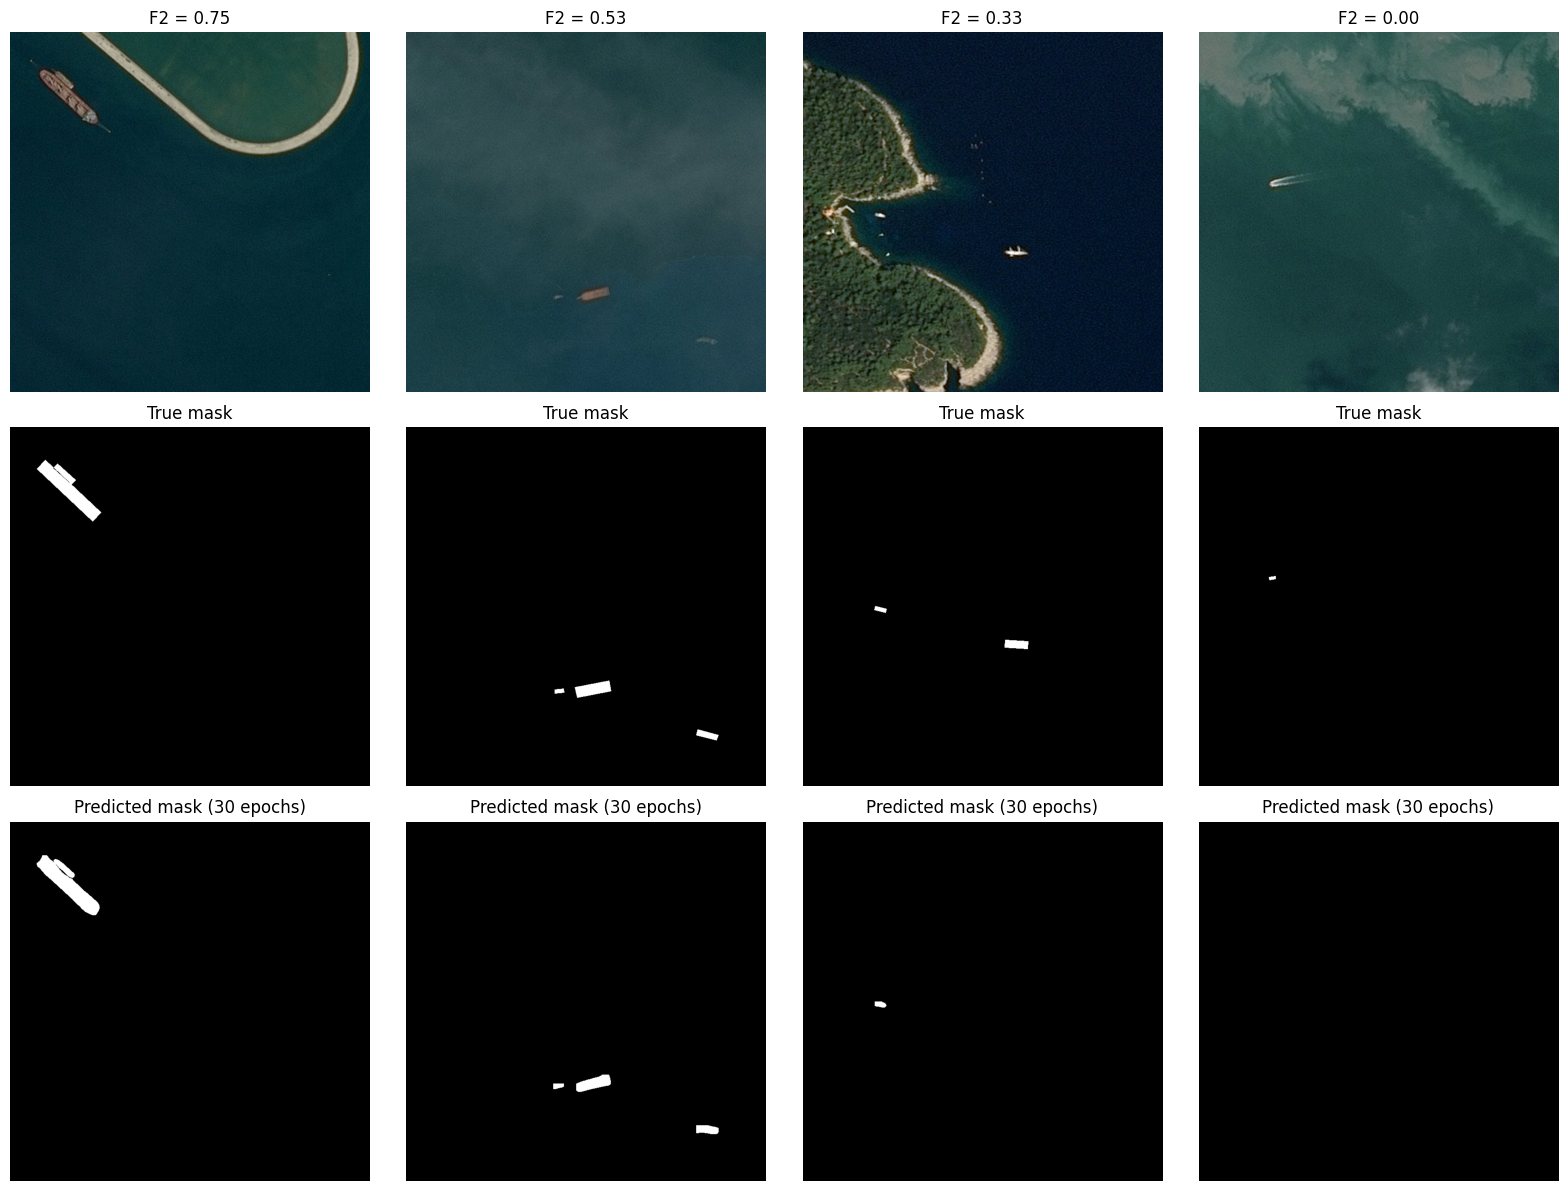

In [18]:
import os
os.environ["YOLO_VERBOSE"] = "False"
from ultralytics import YOLO
import matplotlib.pyplot as plt
from PIL import Image

EVAL = {"name": "yolov8n_seg_768_e30", "imgsz": 768, "conf": 0.5}

df = pd.read_csv(CSV_PATH)
gt = df.dropna().groupby("ImageId")["EncodedPixels"].apply(list)
v = pd.read_csv(f"{WORK_DIR}/val_scores_{EVAL['name']}.csv")
sample = v[v.has_ship].sample(4, random_state=SEED)  # same 4 images as for the 15-epoch model
model = YOLO(f"{WORK_DIR}/runs/{EVAL['name']}/weights/best.pt")

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i, (img_id, f2) in enumerate(zip(sample.ImageId, sample.f2)):
    r = model.predict(f"{IMG_DIR}/{img_id}", imgsz=EVAL["imgsz"], conf=EVAL["conf"],
                      retina_masks=True, verbose=False)[0]
    pred = np.zeros((IMG_SIZE, IMG_SIZE)) if r.masks is None else r.masks.data.cpu().numpy().max(0)
    true = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    for rle in gt[img_id]:
        true |= rle_decode(rle)
    panels = [(Image.open(f"{IMG_DIR}/{img_id}"), f"F2 = {f2:.2f}"), (true, "True mask"), (pred, "Predicted mask (30 epochs)")]
    for row, (im, title) in enumerate(panels):
        axes[row, i].imshow(im, cmap="gray"); axes[row, i].set_title(title); axes[row, i].axis("off")
plt.tight_layout(); plt.savefig(f"{WORK_DIR}/examples_e30.png", dpi=100); plt.show()

- Result: F2 0.861 -> 0.864 (within noise); images with ships 0.330 -> 0.348.
- YOLO's own mask mAP50 rose from about 0.65 to about 0.68, and the curves start to flatten by epoch 30.
- Conclusion: longer training helps YOLO's metric but barely changes F2. The bottleneck is very precise
  masks of tiny ships (F2 needs IoU up to 0.95), not training length.

## 5: Final results

In [19]:
import glob

rows = []
for path in sorted(glob.glob(f"{WORK_DIR}/val_scores_*.csv")):
    v = pd.read_csv(path)
    rows.append({"Experiment": os.path.basename(path)[len("val_scores_"):-len(".csv")],
                 "F2 all images": v.f2.mean(),
                 "F2 images without ships": v.f2[~v.has_ship].mean(),
                 "F2 images with ships": v.f2[v.has_ship].mean()})

results = pd.DataFrame(rows).round(3)
results.to_csv(f"{WORK_DIR}/results.csv", index=False)
print(f"Validation set: {len(v)} images "
      f"({(~v.has_ship).sum()} without ships, {v.has_ship.sum()} with ships)\n")
print(results.to_string(index=False))

Validation set: 2000 images (1594 without ships, 406 with ships)

             Experiment  F2 all images  F2 images without ships  F2 images with ships
               baseline          0.797                    1.000                 0.000
        yolov8n_seg_768          0.861                    0.996                 0.330
yolov8n_seg_768_conf025          0.856                    0.976                 0.386
    yolov8n_seg_768_e30          0.864                    0.995                 0.348


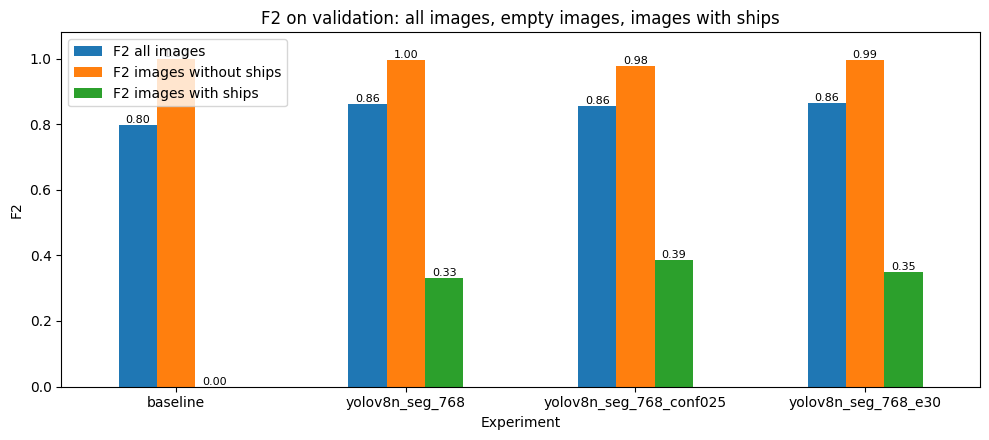

In [20]:
import matplotlib.pyplot as plt

res = pd.read_csv(f"{WORK_DIR}/results.csv").set_index("Experiment")
cols = ["F2 all images", "F2 images without ships", "F2 images with ships"]
ax = res[cols].plot.bar(figsize=(10, 4.5), rot=0)
ax.set(title="F2 on validation: all images, empty images, images with ships", ylabel="F2", ylim=(0, 1.08))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.savefig(f"{WORK_DIR}/results_bars.png", dpi=120)
plt.show()

In [21]:
import shutil

shutil.rmtree(f"{WORK_DIR}/yolo", ignore_errors=True)  # temp YOLO dataset: symlinks + labels
print(sorted(os.listdir(WORK_DIR)))


['__notebook__.ipynb', '__pycache__', 'examples.png', 'examples_e30.png', 'metric.py', 'results.csv', 'results_bars.png', 'runs', 'split.csv', 'val_scores_baseline.csv', 'val_scores_yolov8n_seg_768.csv', 'val_scores_yolov8n_seg_768_conf025.csv', 'val_scores_yolov8n_seg_768_e30.csv', 'yolo_seg_curves.png', 'yolo_seg_curves_e30.png', 'yolov8n-seg.pt']


- Collected all experiments into results.csv and plotted them.
- Main setup (fixed before the experiments): YOLOv8n-seg, 15 epochs, conf 0.5. Experiment results are in the table above.
- The whole notebook was re-run from scratch (Save & Run All) without errors.